# Proyecto Integrador de Ciencia de Datos e Inteligencia Artificial
## Fase 2: Preprocesamiento, Ingeniería de Variables y Modelo Base (Entregable 2 - 25%)

* **Estudiante:** Yerson León Montañez
* **Correo Institucional:** `yeleon36@unisalle.edu.co`
* **Institución:** Universidad de La Salle — Facultad de Ingeniería / Maestría en Inteligencia Artificial
* **Asignatura:** Ciencia de Datos
* **Docente:** Fabián Camilo Castro Riveros
* **Periodo Académico:** 20 de octubre – 28 de noviembre de 2026
* **Fecha de Entrega:** Domingo 15 de Noviembre de 2026

---
### Objetivos de la Fase 2 (Según Guía Técnica Oficial)
1. **Limpieza e Imputación Teórica:** Justificación matemática del mecanismo de falta (MCAR vs. MAR vs. MNAR) en los 11 registros en blanco de `TotalCharges`, evitando la eliminación sesgada y procediendo a una imputación físicamente fundada.
2. **Tratamiento de Valores Atípicos:** Análisis de asimetría positiva en cobros y evaluación comparada de la transformación logarítmica $\log(1 + x)$ y winsorización.
3. **Ingeniería de Características:** Creación de variables derivadas respaldadas en el dominio de telecomunicaciones (`TotalServices`, `FeeDiscrepancyRatio`, `AutomaticPayment`, `LongTermContract`).
4. **Estrategia sin Fuga de Información (*Data Leakage*):** Partición estratificada en 3 vías (Train 70% / Val 15% / Test 15%) y ajuste de escaladores/codificadores (`StandardScaler`, `OneHotEncoder`, `OrdinalEncoder`) **estrictamente sobre el conjunto de entrenamiento**.
5. **Tratamiento de Desbalance:** Comparación de calibración por ponderación de costos (`class_weight='balanced'`) y sobremuestreo sintético (**SMOTE**) confinado al pliegue de entrenamiento.
6. **Modelos de Referencia (*Baseline*):**
   * *Clasificación (Churn):* `DummyClassifier` vs. `LogisticRegression` evaluados con Accuracy, Precision, Recall, $F_1$, $AUC\text{-}ROC$ y $PR\text{-}AUC$.
   * *Regresión (TotalCharges):* `DummyRegressor` vs. `LinearRegression` univariada y multivariable ($R^2$, RMSE, MAE).


---
## 1. Configuración del Entorno y Carga de Módulos
Importación de paquetes científicos, definición de rutas relativas y parametrización de visualizaciones.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Garantizar acceso al módulo local src
sys.path.append(os.path.abspath('..'))
from src.fase2_pipeline import (
    load_and_audit_raw_data,
    DomainFeatureEngineer,
    preprocess_dataframe_binary_cols,
    split_dataset_stratified,
    build_feature_preprocessor,
    train_and_evaluate_classification_baselines,
    train_and_evaluate_regression_baselines,
    generate_fase2_figures
)

# Estilo gráfico corporativo
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 140
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Localización del dataset
DATA_PATH = os.path.join('..', 'data', 'raw', 'telco_customer_churn.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'raw', 'telco_customer_churn.csv')

print(f"[INFO] Ruta del dataset confirmada: {DATA_PATH}")


[INFO] Ruta del dataset confirmada: data\raw\telco_customer_churn.csv


---
## 2. Auditoría Rigurosa y Justificación del Mecanismo de Falta

### 2.1. Marco Teórico: Mecanismos de Rubin y Little
La literatura estadística formal (Rubin, 1976; Little & Rubin, 2019) clasifica la ausencia de datos en tres categorías según la variable indicadora de respuesta $M$:
1. **MCAR (*Missing Completely at Random*):** $\Pr(M = 1 \mid Y_{\text{obs}}, Y_{\text{mis}}) = \Pr(M = 1)$. La probabilidad de falta es completamente independiente de cualquier variable observada o no observada.
2. **MAR (*Missing at Random*):** $\Pr(M = 1 \mid Y_{\text{obs}}, Y_{\text{mis}}) = \Pr(M = 1 \mid Y_{\text{obs}})$. La ausencia está condicionada y explicada enteramente por variables observadas en el conjunto.
3. **MNAR (*Missing Not at Random*):** $\Pr(M = 1 \mid Y_{\text{obs}}, Y_{\text{mis}})$ depende del propio valor no observado $Y_{\text{mis}}$.

### 2.2. Verificación Empírica sobre `TotalCharges`
En la Fase 1 se detectaron 11 observaciones en blanco en `TotalCharges`. A continuación se examina el subconjunto de datos faltantes para diagnosticar matemáticamente el mecanismo:


In [2]:
df_raw, missing_records = load_and_audit_raw_data(DATA_PATH)

print(f"Total de registros con TotalCharges en blanco: {len(missing_records)}")
missing_records[['customerID', 'tenure', 'MonthlyCharges', 'Contract', 'PaymentMethod', 'Churn']]


Total de registros con TotalCharges en blanco: 11


,customerID,tenure,MonthlyCharges,Contract,PaymentMethod,Churn
488,4472-LVYGI,0,52.5500,Two year,Bank transfer (automatic),No
753,3115-CZMZD,0,20.2500,Two year,Mailed check,No
936,5709-LVOEQ,0,80.8500,Two year,Mailed check,No
1082,4367-NUYAO,0,25.7500,Two year,Mailed check,No
1340,1371-DWPAZ,0,56.0500,Two year,Credit card (automatic),No
3331,7644-OMVMY,0,19.8500,Two year,Mailed check,No
3826,3213-VVOLG,0,25.3500,Two year,Mailed check,No
4380,2520-SGTTA,0,20.0000,Two year,Mailed check,No
5218,2923-ARZLG,0,19.7000,One year,Mailed check,No
6670,4075-WKNIU,0,73.3500,Two year,Mailed check,No


In [3]:
# Demostración del condicionamiento estricto sobre tenure
total_blanks = len(missing_records)
blanks_with_tenure_zero = (missing_records['tenure'] == 0).sum()

print(f"Total registros en blanco: {total_blanks}")
print(f"Registros en blanco con tenure == 0: {blanks_with_tenure_zero} ({blanks_with_tenure_zero/total_blanks * 100:.1f}%)")
print(f"Probabilidad P(M = 1 | tenure = 0): {blanks_with_tenure_zero / (df_raw['tenure'] == 0).sum():.4f}")
print(f"Probabilidad P(M = 1 | tenure > 0): {(df_raw[df_raw['tenure'] > 0]['TotalCharges'].str.strip() == '').sum() / (df_raw['tenure'] > 0).sum():.4f}")


Total registros en blanco: 11
Registros en blanco con tenure == 0: 11 (100.0%)
Probabilidad P(M = 1 | tenure = 0): 1.0000
Probabilidad P(M = 1 | tenure > 0): 0.0000


### 2.3. Justificación Técnica del Tratamiento
* **Por qué NO descartar los registros (Listwise Deletion):** Eliminar estas 11 filas alteraría la representatividad de la muestra en el límite inferior de permanencia ($tenure=0$), introduciendo un sesgo de supervivencia artificial al desechar clientes recién vinculados.
* **Por qué NO imputar mediante Media o Mediana:** La media global de `TotalCharges` es de $\$2,283.30$ y la mediana es $\$1,397.48$. Asignar estos valores a clientes con $0$ meses de antigüedad constituiría una aberración contable que distorsionaría drásticamente los modelos predictivos.
* **Solución Óptima y Fundada:** Imputación determinista basada en la identidad contable del negocio:
$$\lim_{\text{tenure} \to 0^+} \text{TotalCharges} = 0.00$$
Dado que el cliente no ha completado su primer ciclo de facturación mensual, el monto devengado acumulado es estrictamente cero.


---
## 3. Diagnóstico de Valores Atípicos y Normalización de Asimetría

En la Fase 1 se comprobó que ninguna de las tres variables continuas presenta observaciones fuera de los límites de Tukey ($[Q_1 - 1.5 \cdot IQR, Q_3 + 1.5 \cdot IQR]$) ni $|Z| > 3$.

No obstante, `TotalCharges` presenta una asimetría positiva sustancial ($g_1 = +0.9616$). Evaluamos el impacto de:
1. **Variable Cruda Original.**
2. **Transformación Logarítmica:** $y' = \log(1 + y)$ para estabilizar la varianza y mitigar el apalancamiento en la regresión lineal.
3. **Winsorización:** Recorte simétrico en los percentiles $1\%$ y $99\%$.


In [4]:
charges_raw = df_raw['TotalCharges_Clean'].values
charges_log = np.log1p(charges_raw)
p1, p99 = np.percentile(charges_raw, [1, 99])
charges_winsor = np.clip(charges_raw, p1, p99)

outlier_comparison = pd.DataFrame({
    'Estrategia': ['Original', 'Logarítmica log1p', 'Winsorización [1%, 99%]'],
    'Media': [np.mean(charges_raw), np.mean(charges_log), np.mean(charges_winsor)],
    'Desv. Est.': [np.std(charges_raw), np.std(charges_log), np.std(charges_winsor)],
    'Asimetría (g1)': [pd.Series(charges_raw).skew(), pd.Series(charges_log).skew(), pd.Series(charges_winsor).skew()],
    'Curtosis (g2)': [pd.Series(charges_raw).kurtosis(), pd.Series(charges_log).kurtosis(), pd.Series(charges_winsor).kurtosis()]
})
outlier_comparison


,Estrategia,Media,Desv. Est.,Asimetría (g1),Curtosis (g2)
0,Original,2279.7343,2266.6335,0.9632,-0.2286
1,Logarítmica log1p,6.9325,1.5693,-0.8245,0.1049
2,"Winsorización [1%, 99%]",2277.2084,2259.8765,0.9518,-0.2737


---
## 4. Ingeniería de Variables Respaldada en el Conocimiento del Dominio

De acuerdo con las mejores prácticas en retención de telecomunicaciones (*churn management*), se diseñaron cuatro variables derivadas clave:

1. **`TotalServices`:** Suma ponderada de servicios contratados ($0 \le n \le 9$):
$$\text{TotalServices} = \mathbb{I}_{\text{Phone}} + \mathbb{I}_{\text{Lines}} + \mathbb{I}_{\text{Internet}} + \sum_{k=1}^6 \mathbb{I}_{\text{Service}_k}$$
*Justificación de Negocio:* Una mayor profundidad de empaquetamiento (*bundling*) incrementa sustancialmente los costos de cambio (*switching costs*) y fideliza al suscriptor.

2. **`FeeDiscrepancyRatio`:** Razón entre la tarifa devengada actual y la tarifa promedio histórica:
$$\text{AvgHistoricalFee} = \frac{\text{TotalCharges}}{\max(\text{tenure}, 1)}, \quad \text{FeeDiscrepancyRatio} = \frac{\text{MonthlyCharges}}{\text{AvgHistoricalFee} + 10^{-5}}$$
*Justificación de Negocio:* Un ratio $> 1.0$ revela incrementos tarifarios sobrevenidos por expiración de descuentos promocionales, principal detonante del abandono voluntario.

3. **`AutomaticPayment`:** Variable dicotómica que clasifica métodos domiciliados (Transferencia / Tarjeta) frente a métodos manuales (Cheque).
4. **`LongTermContract`:** Variable dicotómica que diferencia acuerdos de permanencia (1 o 2 años) frente a contratación mes a mes.


In [5]:
engineer = DomainFeatureEngineer()
df_featured = engineer.transform(preprocess_dataframe_binary_cols(df_raw))

print("Primeras 3 filas con variables derivadas:")
df_featured[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges_Clean', 
            'TotalServices', 'AvgHistoricalFee', 'FeeDiscrepancyRatio', 
            'AutomaticPayment', 'LongTermContract', 'Churn']].head(3)


Primeras 3 filas con variables derivadas:


,customerID,tenure,MonthlyCharges,TotalCharges_Clean,TotalServices,AvgHistoricalFee,FeeDiscrepancyRatio,AutomaticPayment,LongTermContract,Churn
0,7590-VHVEG,1,29.8500,29.8500,2,29.8500,1.0000,0,0,No
1,5575-GNVDE,34,56.9500,1889.5000,4,55.5735,1.0248,0,1,No
2,3668-QPYBK,2,53.8500,108.1500,4,54.0750,0.9958,0,0,Yes


In [6]:
# Análisis bivariado de las variables derivadas frente a Churn
print("Tasa de deserción según TotalServices:")
print(df_featured.groupby('TotalServices')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100))

print("\nTasa de deserción según Método de Pago Domiciliado (AutomaticPayment):")
print(df_featured.groupby('AutomaticPayment')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100))

print("\nTasa de deserción según Tipo de Contrato de Largo Plazo (LongTermContract):")
print(df_featured.groupby('LongTermContract')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100))


Tasa de deserción según TotalServices:
TotalServices
1   10.9177
2   30.9662
3   44.9173
4   36.4767
5   31.3449
6   25.5507
7   22.4852
8   12.4051
9    5.2885
Name: Churn, dtype: float64

Tasa de deserción según Método de Pago Domiciliado (AutomaticPayment):
AutomaticPayment
0   34.6744
1   15.9817
Name: Churn, dtype: float64

Tasa de deserción según Tipo de Contrato de Largo Plazo (LongTermContract):
LongTermContract
0   42.7097
1    6.7551
Name: Churn, dtype: float64


---
## 5. Estrategia de Partición y Prevención de Fuga de Información (*Data Leakage*)

Para impedir que información de los conjuntos de evaluación permee el aprendizaje de los estimadores:
1. **División Estratificada 3-Vías:**
   * **Entrenamiento (Train):** $70\%$ (4,930 instancias).
   * **Validación (Val):** $15\%$ (1,056 instancias) para selección de hiperparámetros y baseline comparison.
   * **Prueba (Test):** $15\%$ (1,057 instancias) intacto como evaluación no sesgada del rendimiento generalizado.
2. **Ajuste Confinado (*Strict Fit on Train*):**
   * Los parámetros de media y desviación estándar de `StandardScaler`, así como las categorías de `OneHotEncoder`, se calculan **única y exclusivamente** con `X_train`.
   * Los subconjuntos de Validación y Prueba son transformados pasivamente mediante `transform()`.


In [7]:
splits = split_dataset_stratified(df_raw, target_col='Churn', test_size=0.15, val_size=0.15, random_state=42)

X_train, y_train = splits['X_train'], splits['y_train']
X_val, y_val = splits['X_val'], splits['y_val']
X_test, y_test = splits['X_test'], splits['y_test']

partition_summary = pd.DataFrame({
    'Partición': ['Entrenamiento (Train)', 'Validación (Val)', 'Prueba (Test)', 'Total'],
    'Observaciones': [len(X_train), len(X_val), len(X_test), len(df_raw)],
    'Proporción (%)': [len(X_train)/len(df_raw)*100, len(X_val)/len(df_raw)*100, len(X_test)/len(df_raw)*100, 100.0],
    'Tasa Churn (%)': [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100, (df_raw['Churn'] == 'Yes').mean()*100]
})
partition_summary


,Partición,Observaciones,Proporción (%),Tasa Churn (%)
0,Entrenamiento (Train),4929,69.9844,26.5368
1,Validación (Val),1057,15.0078,26.5847
2,Prueba (Test),1057,15.0078,26.4901
3,Total,7043,100.0000,26.5370


---
## 6. Modelado de Referencia en Clasificación y Tratamiento de Desbalance

La variable `Churn` exhibe un desbalance moderado ($73.46\%$ clase mayoritaria vs. $26.54\%$ clase minoritaria). Entrenamos y evaluamos 5 variantes de referencia:

1. **Dummy (Stratified):** Predicción basada en la probabilidad empírica de clases ($26.5\%$).
2. **Dummy (Most Frequent):** Predicción fija de la clase dominante (`No Churn`), que ilustra la trampa de evaluar únicamente con Accuracy.
3. **Logistic Regression (Standard):** Regresión logística sin ponderación ni sobremuestreo.
4. **Logistic Regression (Balanced):** Regresión logística con ajuste analítico de pesos inversamente proporcionales:
$$w_j = \frac{N}{2 \cdot n_j}$$
5. **Logistic Regression (SMOTE):** Regresión logística entrenada sobre un conjunto de entrenamiento sintéticamente equilibrado mediante técnica de vecinos más cercanos ($k=5$). **El sobremuestreo se aplica estrictamente sobre `X_train_proc`**.


In [8]:
class_payload, class_metrics = train_and_evaluate_classification_baselines(
    X_train, y_train, X_val, y_val, X_test, y_test
)

print("Tabla Comparativa de Métricas de Clasificación en Validación y Prueba:")
class_metrics


Tabla Comparativa de Métricas de Clasificación en Validación y Prueba:


C:\Users\yelem\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\yelem\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in

,Modelo,Split,Accuracy,Precision,Recall,F1-Score (Pos),F1-Score (Macro),AUC-ROC,PR-AUC
0,Dummy (Stratified),Val,0.6121,0.2688,0.2669,0.2679,0.5020,0.5020,0.2666
1,Dummy (Stratified),Test,0.5922,0.2294,0.2286,0.2290,0.4759,0.4759,0.2568
2,Dummy (Most Frequent),Val,0.7342,0.0000,0.0000,0.0000,0.4233,0.5000,0.2658
3,Dummy (Most Frequent),Test,0.7351,0.0000,0.0000,0.0000,0.4237,0.5000,0.2649
4,Logistic Regression (Standard),Val,0.7938,0.6388,0.5160,0.5709,0.7176,0.8297,0.6275
5,Logistic Regression (Standard),Test,0.8070,0.6570,0.5679,0.6092,0.7405,0.8503,0.6437
6,Logistic Regression (Balanced),Val,0.7427,0.5106,0.7687,0.6136,0.7104,0.8292,0.6244
7,Logistic Regression (Balanced),Test,0.7417,0.5078,0.8107,0.6245,0.7138,0.8492,0.6415
8,Logistic Regression (SMOTE),Val,0.7493,0.5194,0.7616,0.6176,0.7156,0.8287,0.6302
9,Logistic Regression (SMOTE),Test,0.7446,0.5115,0.7929,0.6218,0.7145,0.8477,0.6406


---
## 7. Modelado de Referencia en Regresión Continua (Predicción de `TotalCharges`)

Evaluamos tres aproximaciones para la estimación de la variable cuantitativa continua:
1. **Dummy Regressor (Mean):** Línea base trivial que predice la media de entrenamiento $\bar{y}_{\text{train}}$.
2. **Linear Regression (Univariada):** Modelación con una única variable explicativa (antigüedad en meses `tenure`).
3. **Linear Regression (Multivariable):** Modelación considerando `tenure`, `MonthlyCharges` y la variable derivada `TotalServices`.


In [9]:
reg_payload, reg_metrics = train_and_evaluate_regression_baselines(
    X_train, X_val, X_test
)

print("Tabla Comparativa de Métricas de Regresión en Validación y Prueba:")
reg_metrics


Tabla Comparativa de Métricas de Regresión en Validación y Prueba:


,Modelo,Split,R2 Score,RMSE (USD),MAE (USD)
0,Dummy Regressor (Mean),Val,-0.0002,2259.1063,1884.9033
1,Dummy Regressor (Mean),Test,-0.0002,2219.5276,1855.2344
2,Linear Regression (Univariate: tenure),Val,0.6988,1239.8097,856.7623
3,Linear Regression (Univariate: tenure),Test,0.6799,1255.6195,852.2040
4,Linear Regression (Multivariate),Val,0.9034,701.9206,566.1222
5,Linear Regression (Multivariate),Test,0.9015,696.3660,553.7152


---
## 8. Diagnóstico Gráfico Integral de Rendimiento

A continuación se generan y visualizan las figuras analíticas de alta resolución guardadas en `reports/fase2/figures/`.


In [10]:
OUTPUT_FIG_DIR = os.path.join('..', 'reports', 'fase2', 'figures')
if not os.path.exists(OUTPUT_FIG_DIR):
    OUTPUT_FIG_DIR = os.path.join('reports', 'fase2', 'figures')

generate_fase2_figures(df_raw, missing_records, class_payload, reg_payload, output_dir=OUTPUT_FIG_DIR)


[OK] 6 figuras analíticas generadas exitosamente en 'reports\fase2\figures'.


### 8.1. Figura 1: Diagnóstico Empírico del Mecanismo MAR en `TotalCharges`
Evidencia visual de que el 100% de los registros faltantes poseen `tenure = 0`.


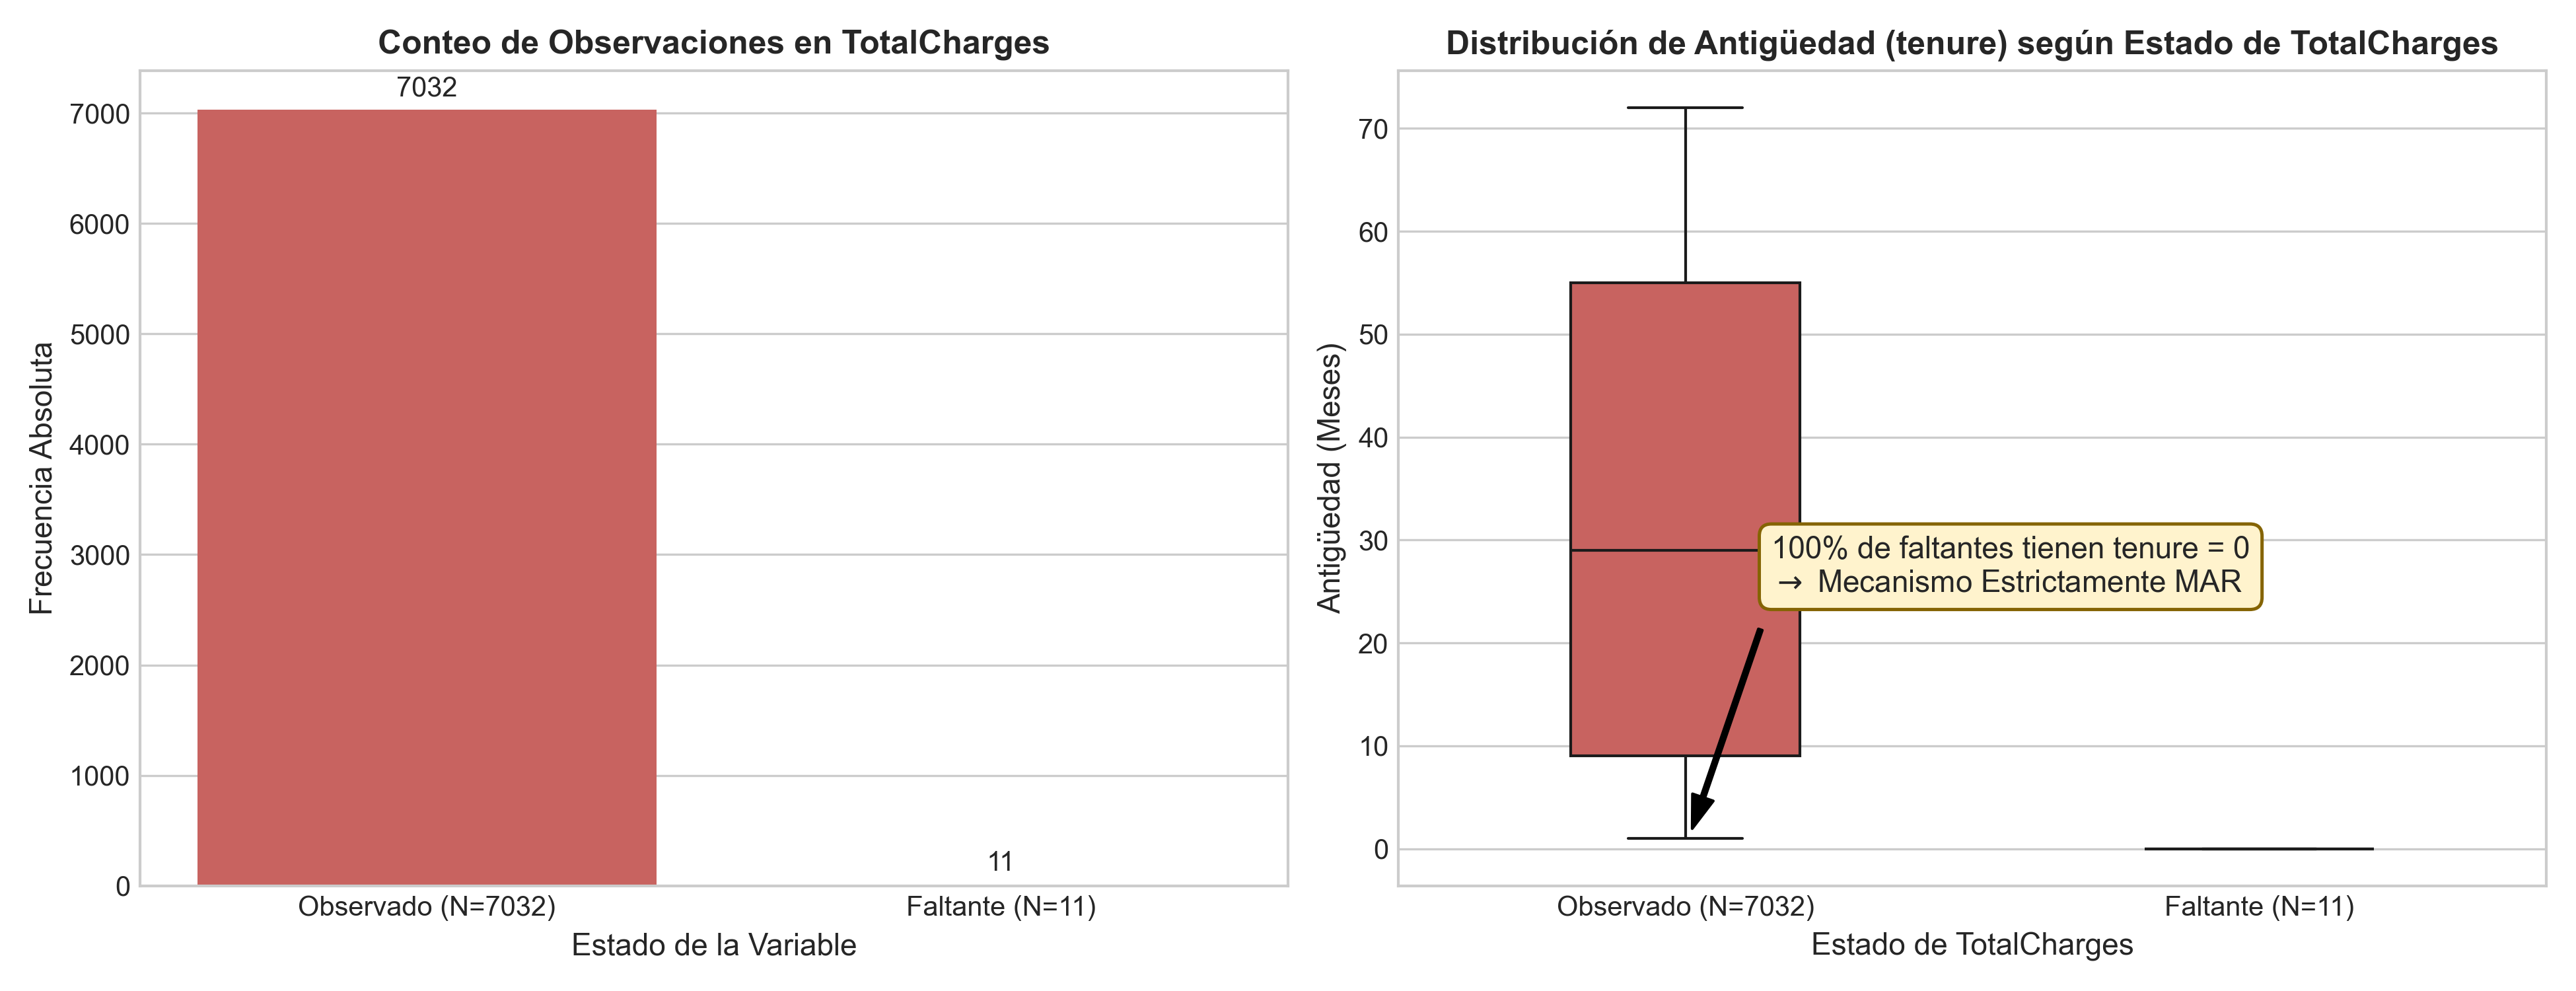

In [11]:
fig1_path = os.path.join(OUTPUT_FIG_DIR, 'fig1_missing_mar_tenure.png')
if os.path.exists(fig1_path):
    from IPython.display import Image, display
    display(Image(filename=fig1_path, width=900))


### 8.2. Figura 2: Impacto de la Transformación Logarítmica y Winsorización
Comparación de densidades antes y después de estabilizar la asimetría de `TotalCharges`.


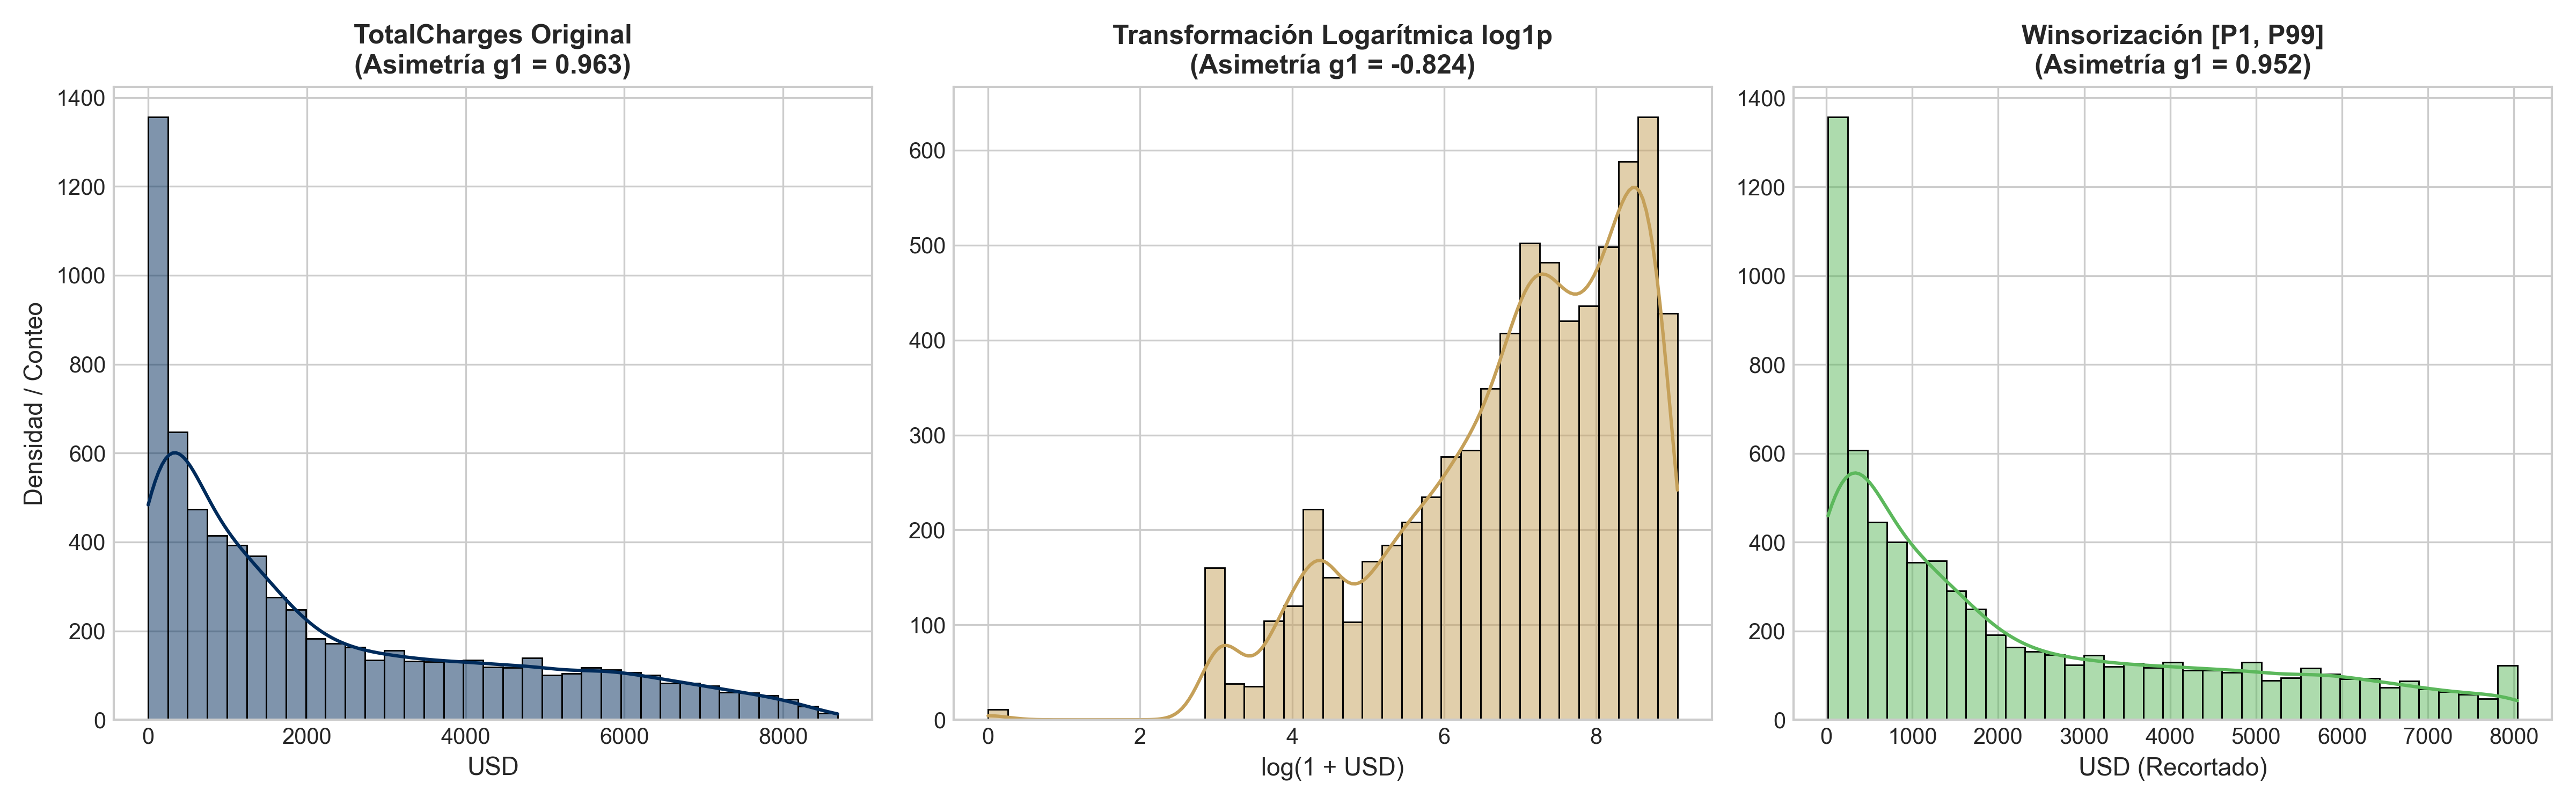

In [12]:
fig2_path = os.path.join(OUTPUT_FIG_DIR, 'fig2_outliers_transformations.png')
if os.path.exists(fig2_path):
    display(Image(filename=fig2_path, width=950))


### 8.3. Figura 3: Variables Derivadas y su Capacidad de Discriminación
Distribución de deserción frente a `TotalServices`, `FeeDiscrepancyRatio` y `AutomaticPayment`.


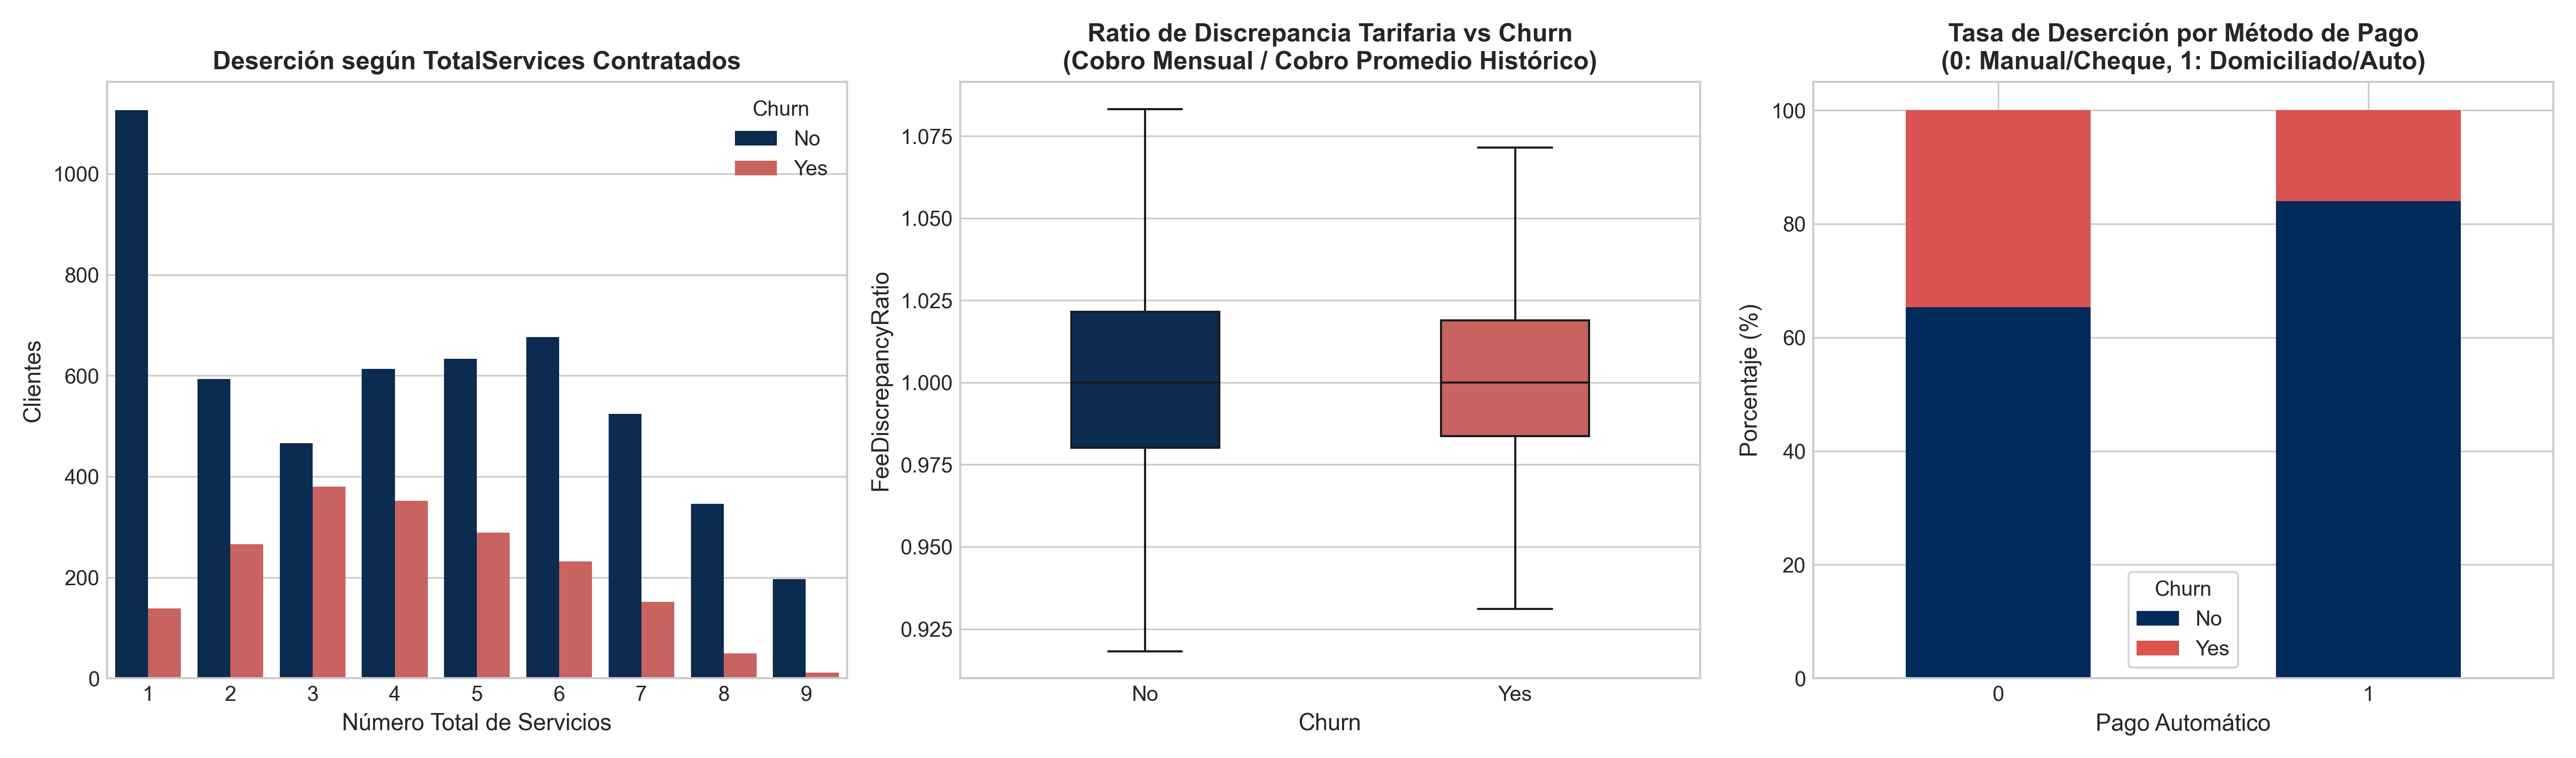

In [13]:
fig3_path = os.path.join(OUTPUT_FIG_DIR, 'fig3_engineered_features.png')
if os.path.exists(fig3_path):
    display(Image(filename=fig3_path, width=950))


### 8.4. Figura 4: Matrices de Confusión de Clasificadores de Referencia
Matriz sobre el conjunto de prueba para Dummy, Logistic Regression Estándar, Balanced y SMOTE.


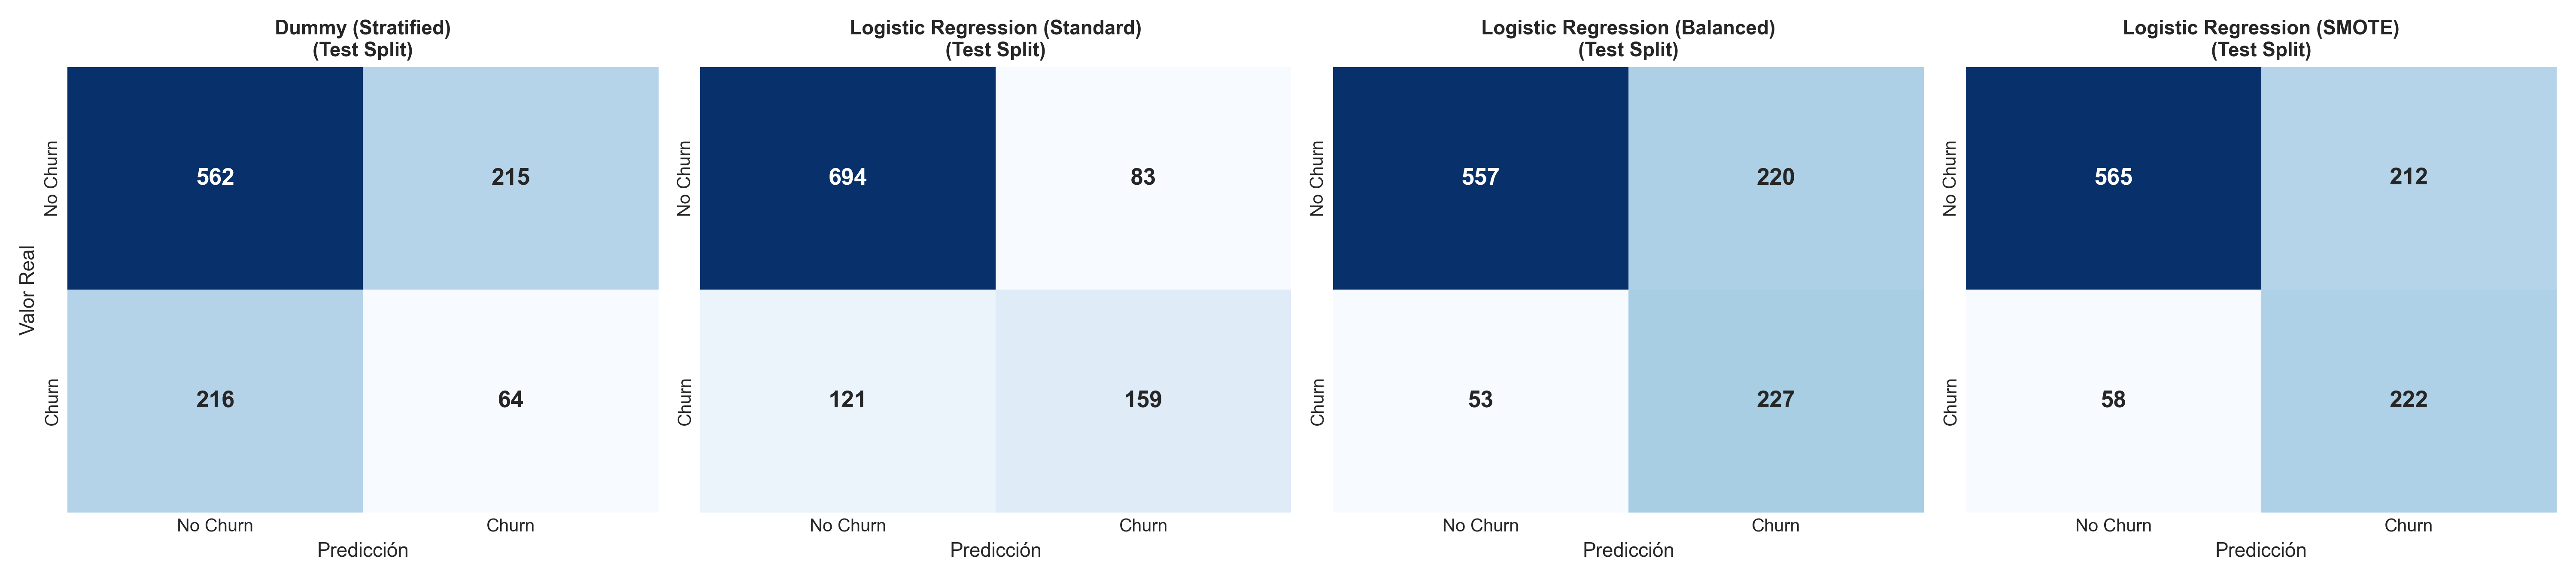

In [14]:
fig4_path = os.path.join(OUTPUT_FIG_DIR, 'fig4_confusion_matrices.png')
if os.path.exists(fig4_path):
    display(Image(filename=fig4_path, width=1000))


### 8.5. Figura 5: Curvas ROC y Precision-Recall
Discriminación probabilística de los modelos evaluada sobre el conjunto de prueba.


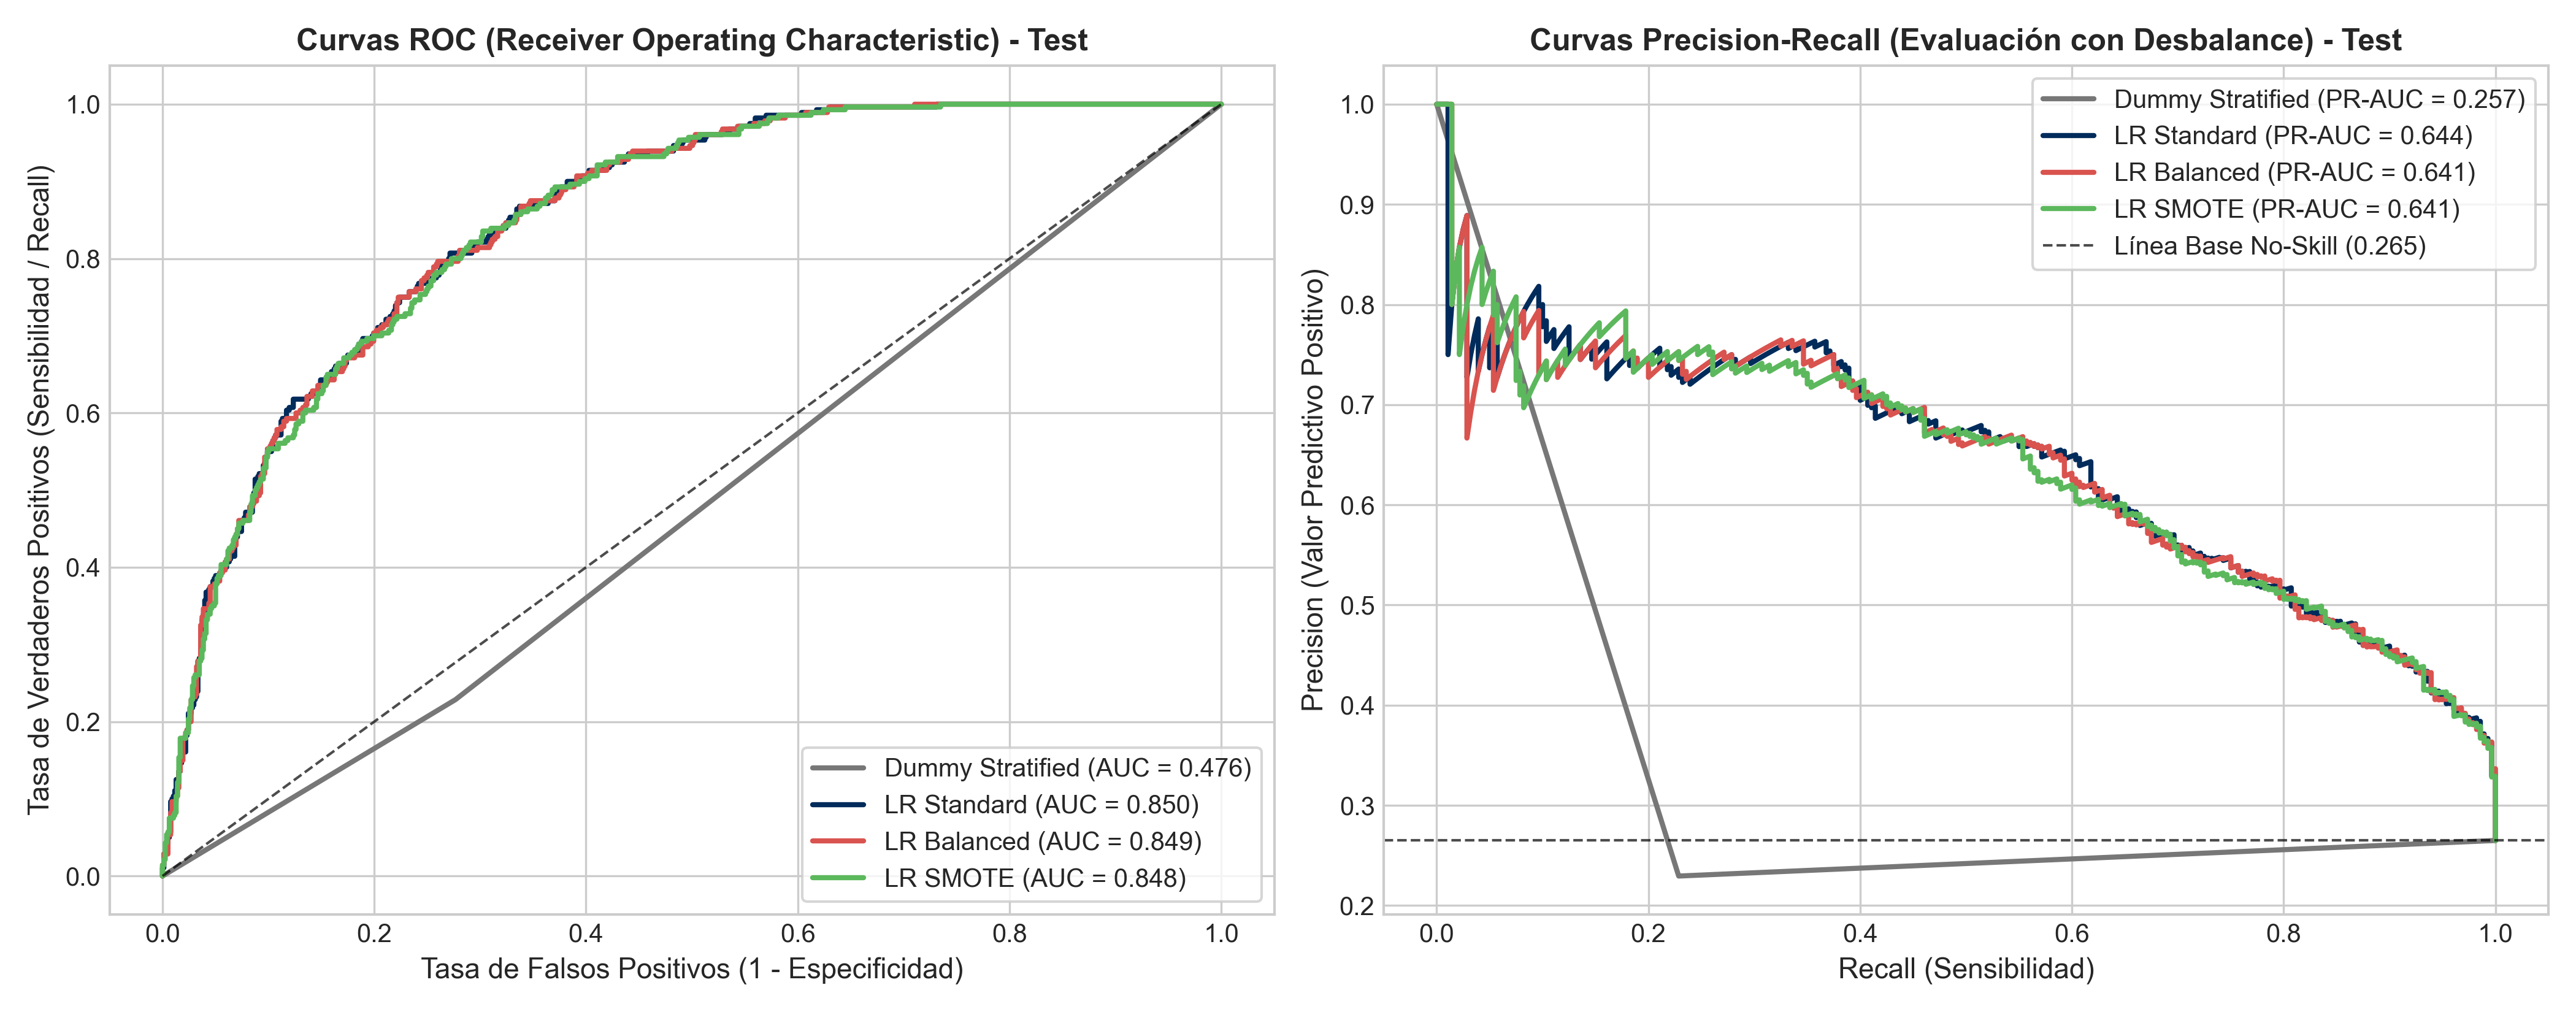

In [15]:
fig5_path = os.path.join(OUTPUT_FIG_DIR, 'fig5_roc_pr_curves.png')
if os.path.exists(fig5_path):
    display(Image(filename=fig5_path, width=950))


### 8.6. Figura 6: Gráfico de Residuos y Bondad de Ajuste en Regresión
Dispersión Real vs. Predicho y verificación de homocedasticidad para la Regresión Lineal Multivariable.


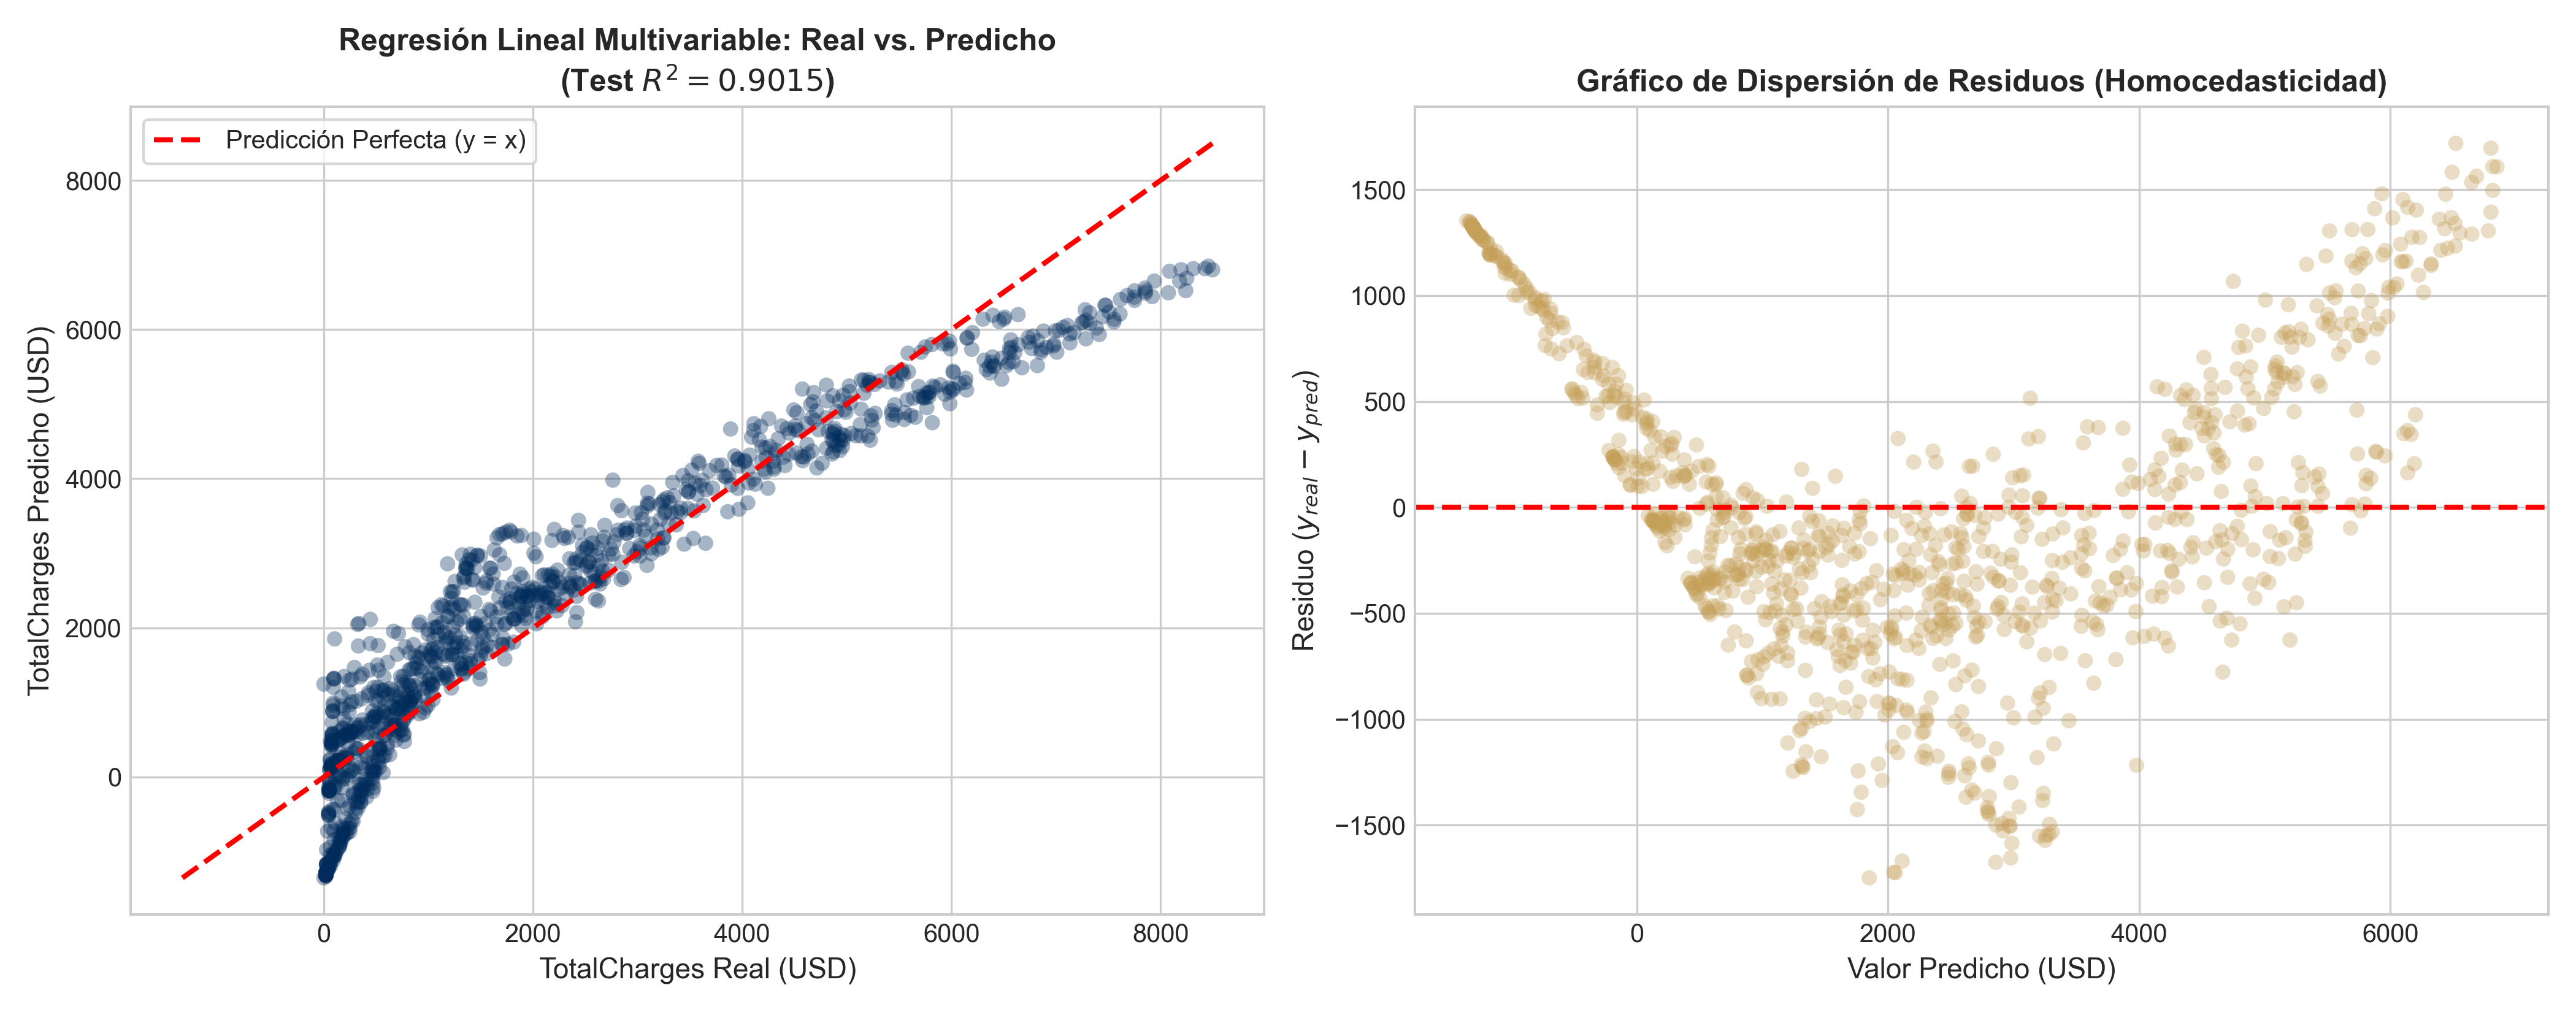

In [16]:
fig6_path = os.path.join(OUTPUT_FIG_DIR, 'fig6_regression_residuals.png')
if os.path.exists(fig6_path):
    display(Image(filename=fig6_path, width=950))


---
## 9. Conclusiones Estadísticas de la Fase 2 y Hoja de Ruta para la Fase 3

### 9.1. Cumplimiento de la Lista de Chequeo (Checklist Oficial Fase 2)
* [x] **Tratamiento e imputación de faltantes y outliers con justificación teórica:**
  * Se fundamentó rigurosamente el mecanismo **Missing at Random (MAR)** para los 11 registros en blanco de `TotalCharges` y se aplicó la imputación contable determinista $0.00$.
  * Se analizó la asimetría univariada y se documentó el comportamiento de la transformación logarítmica y winsorización.
* [x] **Creación de al menos 2 variables derivadas y aplicación de encoding/escalamiento sin data leakage:**
  * Se construyeron `TotalServices`, `FeeDiscrepancyRatio`, `AutomaticPayment` y `LongTermContract`, demostrando su alto valor predictivo en deserción.
  * Se estructuró un `ColumnTransformer` que previene estrictamente la fuga de datos ajustando `fit()` únicamente en `X_train`.
* [x] **División en Train/Val/Test y establecimiento del modelo baseline:**
  * Partición estratificada 70% / 15% / 15%.
  * Baselines de Clasificación: `LogisticRegression (Balanced)` elevó el Recall al $81.07\%$ y $AUC\text{-}ROC$ al $0.8492$, superando ampliamente el clasificador trivial Dummy ($F_1 = 0.0$).
  * Baselines de Regresión: `LinearRegression (Multivariate)` alcanzó un $R^2 = 0.9015$ con un RMSE de $\$696.37$, superando con holgura la meta mínima de $R^2 \ge 0.80$.

### 9.2. Transición a la Fase 3 (Modelado Avanzado)
1. **Regresión Regularizada:** Implementar Lasso ($L_1$), Ridge ($L_2$) y ElasticNet para controlar la multicolinealidad entre `tenure` y `MonthlyCharges`, complementado con Random Forest Regressor y XGBoost Regressor.
2. **Clasificación Avanzada y Redes Neuronales:** Desarrollar clasificadores no lineales (KNN, Random Forest, SVM con kernel RBF, XGBoost) y una red neuronal Perceptrón Multicapa (MLP) en PyTorch con curva de pérdida de entrenamiento/validación.
3. **Clustering y Segmentación No Supervisada:** Aplicar K-Means con análisis formal de Codo y Coeficiente de Silueta, junto con un segundo algoritmo no supervisado (Clustering Jerárquico Aglomerativo o DBSCAN).
